# Parameters per GPT2 model version

In [1]:
import pandas as pd

url = "http://data.gdeltproject.org/gdeltv2/lastupdate.txt"

updates = pd.read_csv(
    url,
    sep=" ",
    header=None,
    names=["size", "hash", "url"]
)

print(updates)

      size                              hash  \
0    57336  35453e6c673cc1096ea113841c6d8b56   
1    76384  ab28ccd1e75822ab9191a90b619cc50e   
2  3927803  f980f9060ac26ce50a7bd358f1fe7c6f   

                                                 url  
0  http://data.gdeltproject.org/gdeltv2/202607150...  
1  http://data.gdeltproject.org/gdeltv2/202607150...  
2  http://data.gdeltproject.org/gdeltv2/202607150...  


In [ ]:
!pip -q install transformers

In [ ]:
from transformers import AutoModelForCausalLM, GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
model_ids = {
    "small": "gpt2",
    "medium": "gpt2-medium",
    "large": "gpt2-large",
    "xl": "gpt2-xl"
}

models = {}

for id, name in model_ids.items():
   models[id] = AutoModelForCausalLM.from_pretrained(name)

models

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/6.43G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

{'small': GPT2LMHeadModel(
   (transformer): GPT2Model(
     (wte): Embedding(50257, 768)
     (wpe): Embedding(1024, 768)
     (drop): Dropout(p=0.1, inplace=False)
     (h): ModuleList(
       (0-11): 12 x GPT2Block(
         (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
         (attn): GPT2Attention(
           (c_attn): Conv1D(nf=2304, nx=768)
           (c_proj): Conv1D(nf=768, nx=768)
           (attn_dropout): Dropout(p=0.1, inplace=False)
           (resid_dropout): Dropout(p=0.1, inplace=False)
         )
         (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
         (mlp): GPT2MLP(
           (c_fc): Conv1D(nf=3072, nx=768)
           (c_proj): Conv1D(nf=768, nx=3072)
           (act): NewGELUActivation()
           (dropout): Dropout(p=0.1, inplace=False)
         )
       )
     )
     (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
   )
   (lm_head): Linear(in_features=768, out_features=50257, bias=False)
 ),
 'medium': GPT2L

In [ ]:
for id, name in model_ids.items():
  print(f"{sum(p.numel() for p in models[id].parameters()):>15,} parameters in {name}")

    124,439,808 parameters in gpt2
    354,823,168 parameters in gpt2-medium
    774,030,080 parameters in gpt2-large
  1,557,611,200 parameters in gpt2-xl


# GPT2-Small Params

In [ ]:
models.keys()

dict_keys(['small', 'medium', 'large', 'xl'])

In [ ]:
!pip -q install torchinfo
from torchinfo import summary
import torch

x = tokenizer.encode('Testing input text to check number of params of gpt2-small')
x = torch.tensor(x).unsqueeze(0)

sumry = summary(models['small'], input_data = x, col_names = ['input_size', 'output_size', 'num_params'])
print(sumry)

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #
GPT2LMHeadModel                                    [1, 14]                   --                        --
├─GPT2Model: 1-1                                   [1, 14]                   --                        --
│    └─Embedding: 2-1                              [1, 14]                   [1, 14, 768]              38,597,376
│    └─Embedding: 2-2                              [1, 14]                   [1, 14, 768]              786,432
│    └─Dropout: 2-3                                [1, 14, 768]              [1, 14, 768]              --
│    └─ModuleList: 2-4                             --                        --                        --
│    │    └─GPT2Block: 3-1                         [1, 14, 768]              [1, 14, 768]              7,087,872
│    │    └─GPT2Block: 3-2                         [1, 14, 768]              [1, 14, 768]              7,087,872
│    │    └─GP

In [ ]:
final_layer_params = torch.numel(models['small'].lm_head.weight)

print(f"Total parameters excluding tied lm_head params: {sumry.total_params - final_layer_params:_}")

Total parameters excluding tied lm_head params: 124_439_808


# Token Embeddings vs Head

[Text(0.5, 0, 'Dimension'),
 Text(0, 0.5, 'Value'),
 (0.0, 768.0),
 Text(0.5, 1.0, 'Correlation = 1.000')]

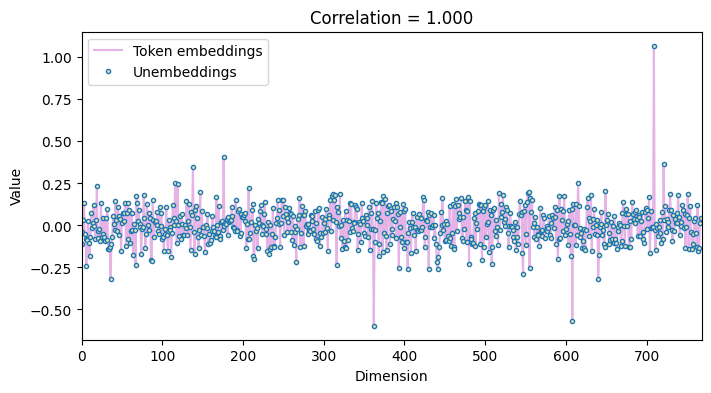

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,4))

tok_w = models['small'].transformer.wte.weight[0].detach()
head  = models['small'].lm_head.weight[0].detach()

plt.plot(tok_w, color = [.9,.7,.9], label = 'Token embeddings')
plt.plot(head, 'o', markerfacecolor = [.9,.9,.7], markersize = 3, label = 'Unembeddings')

plt.legend()
plt.gca().set(xlabel='Dimension', ylabel='Value', xlim = [0,len(tok_w)],
              title = f'Correlation = {np.corrcoef(tok_w, head)[0,1]:.3f}')

## Total number of weights and biases

In [ ]:
for name in model_ids.keys():

    weights = 0
    biases = 0

    for param_name, param in models[name].named_parameters():
        if 'weight' in param_name:
            weights += param.numel()
        elif 'bias' in param_name:
            biases += param.numel()

    total = weights + biases

    print(f'** Model "{name}":')
    print(f"Total weights: {weights:<10} ({weights / total * 100:.2f}% of all params)")
    print(f"Total biases:  {biases:<10} ({biases / total * 100:.2f}% of all params)")
    print()

** Model "small":
Total weights: 124337664  (99.92% of all params)
Total biases:  102144     (0.08% of all params)

** Model "medium":
Total weights: 354551808  (99.92% of all params)
Total biases:  271360     (0.08% of all params)

** Model "large":
Total weights: 773521920  (99.93% of all params)
Total biases:  508160     (0.07% of all params)

** Model "xl":
Total weights: 1556764800 (99.95% of all params)
Total biases:  846400     (0.05% of all params)



# Total number of params in attention vs in MLP blocks

In [ ]:
for name in model_ids.keys():

    attn_params = 0
    mlp_params = 0
    total_params = sum(p.numel() for p in models[name].parameters())

    for param_name, param in models[name].named_parameters():
        if ".attn." in param_name:
            attn_params += param.numel()
        elif ".mlp." in param_name:
            mlp_params += param.numel()

    print(f'** Model "{name}":')
    print(f"Total attention params: {attn_params:<10} ({attn_params / total_params * 100:.2f}% of all params)")
    print(f"Total MLP params:       {mlp_params:<10} ({mlp_params / total_params * 100:.2f}% of all params)")
    print()

** Model "small":
Total attention params: 28348416   (22.78% of all params)
Total MLP params:       56669184   (45.54% of all params)

** Model "medium":
Total attention params: 100761600  (28.40% of all params)
Total MLP params:       201449472  (56.77% of all params)

** Model "large":
Total attention params: 236113920  (30.50% of all params)
Total MLP params:       472089600  (60.99% of all params)

** Model "xl":
Total attention params: 491827200  (31.58% of all params)
Total MLP params:       983424000  (63.14% of all params)



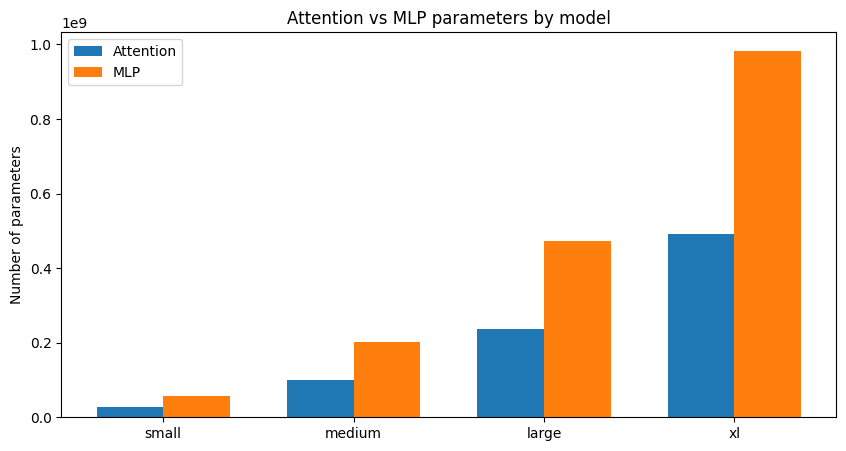

In [ ]:
import matplotlib.pyplot as plt

model_names = []
attn_counts = []
mlp_counts = []

for name in model_ids.keys():

    attn_params = 0
    mlp_params = 0

    for param_name, param in models[name].named_parameters():
        if ".attn." in param_name:
            attn_params += param.numel()
        elif ".mlp." in param_name:
            mlp_params += param.numel()

    model_names.append(name)
    attn_counts.append(attn_params)
    mlp_counts.append(mlp_params)


x = range(len(model_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar([i - width/2 for i in x], attn_counts, width, label="Attention")
plt.bar([i + width/2 for i in x], mlp_counts, width, label="MLP")

plt.xticks(x, model_names)
plt.ylabel("Number of parameters")
plt.title("Attention vs MLP parameters by model")
plt.legend()

plt.show()

# Layernorm parameters

In [ ]:
for name in model_ids.keys():

    weights = 0
    biases = 0

    for param_name, param in models[name].named_parameters():
        if 'ln' in param_name:
          if 'weight' in param_name:
              weights += param.numel()
          elif 'bias' in param_name:
              biases += param.numel()

    total = weights + biases

    print(f'** Model "{name}":')
    print(f"Total weights: {weights:<10} ({weights / total * 100:.2f}% of all params)")
    print(f"Total biases:  {biases:<10} ({biases / total * 100:.2f}% of all params)")
    print()

** Model "small":
Total weights: 19200      (50.00% of all params)
Total biases:  19200      (50.00% of all params)

** Model "medium":
Total weights: 50176      (50.00% of all params)
Total biases:  50176      (50.00% of all params)

** Model "large":
Total weights: 93440      (50.00% of all params)
Total biases:  93440      (50.00% of all params)

** Model "xl":
Total weights: 155200     (50.00% of all params)
Total biases:  155200     (50.00% of all params)



# GPT2 Trained Weights Distributions

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
from transformers import AutoModelForCausalLM

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [ ]:
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
gpt2

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

## Distributions of token and position embeddings

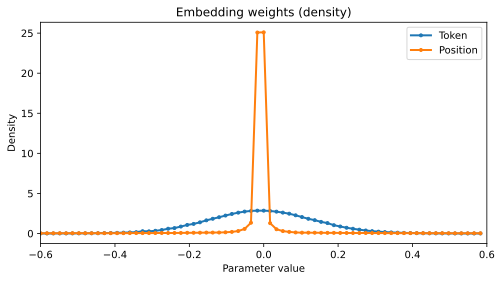

In [ ]:
bins = np.linspace(-.6,.6,71)

y_e, x_e = np.histogram(gpt2.transformer.wte.weight.detach(), bins, density = True)
y_p, x_p = np.histogram(gpt2.transformer.wpe.weight.detach(), bins, density = True)

plt.figure(figsize = (8,4))
plt.plot(bins[:-1], y_e, '.-', linewidth=2, label = 'Token')
plt.plot(bins[:-1], y_p, '.-', linewidth=2, label = 'Position'),

plt.legend()
plt.gca().set(xlabel = 'Parameter value', ylabel = 'Density', xlim = bins[[0,-1]], title = "Embedding weights (density)")
plt.show()

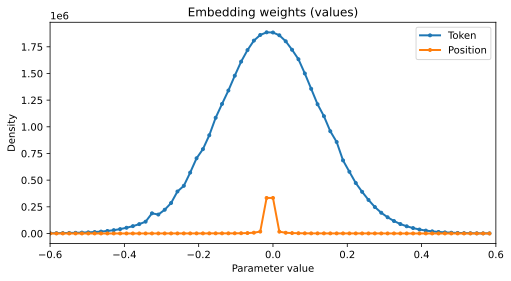

In [ ]:
bins = np.linspace(-.6,.6,71)

y_e, x_e = np.histogram(gpt2.transformer.wte.weight.detach(), bins)
y_p, x_p = np.histogram(gpt2.transformer.wpe.weight.detach(), bins)

plt.figure(figsize = (8,4))
plt.plot(bins[:-1], y_e, '.-', linewidth=2, label = 'Token')
plt.plot(bins[:-1], y_p, '.-', linewidth=2, label = 'Position'),

plt.legend()
plt.gca().set(xlabel = 'Parameter value', ylabel = 'Density', xlim = bins[[0,-1]], title = "Embedding weights (values)")
plt.show()

## Distribution of attention and MLP weights

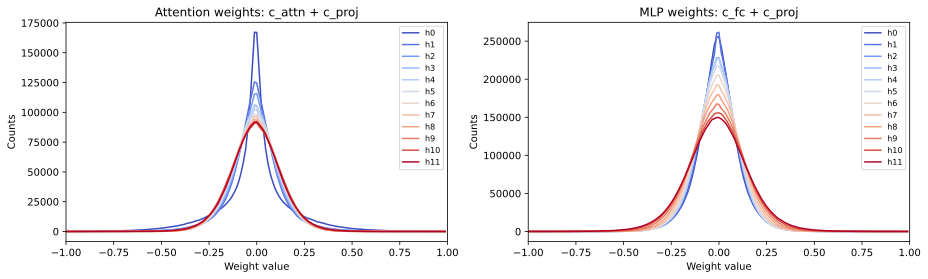

In [ ]:
_, axs = plt.subplots(1, 2, figsize=(13, 4))

bins = np.linspace(-1, 1, 171)
colors = plt.cm.coolwarm(np.linspace(0, 1, len(gpt2.transformer.h)))

for h_idx in range(len(gpt2.transformer.h)):

  # attention weights: c_attn = QKV projection
  attn_w = torch.concatenate((gpt2.transformer.h[h_idx].attn.c_attn.weight.detach().flatten(),
                              gpt2.transformer.h[h_idx].attn.c_proj.weight.detach().flatten()))
  y, x = np.histogram(attn_w, bins=bins)
  axs[0].plot(x[:-1], y, color=colors[h_idx], label=f'h{h_idx}')

  # MLP weights: c_fc = first MLP projection
  mlp_w = torch.concatenate((gpt2.transformer.h[h_idx].mlp.c_fc.weight.detach().flatten(),
                             gpt2.transformer.h[h_idx].mlp.c_proj.weight.detach().flatten()))
  y, x = np.histogram(mlp_w, bins=bins)
  axs[1].plot(x[:-1], y, color=colors[h_idx], label=f'h{h_idx}')

for a in axs:
  a.legend(fontsize=8)
  a.set(xlim=bins[[0, -1]], xlabel='Weight value', ylabel='Counts')

axs[0].set_title('Attention weights: c_attn + c_proj')
axs[1].set_title('MLP weights: c_fc + c_proj')

plt.tight_layout()
plt.show()

`c_attn` - matrix from Attention class - `y = F.scaled_dot_product_attention(q, k, v, is_causal = True)`

`c_proj` - final `y`

In [ ]:
gpt2.transformer.h[0].attn

GPT2Attention(
  (c_attn): Conv1D(nf=2304, nx=768)
  (c_proj): Conv1D(nf=768, nx=768)
  (attn_dropout): Dropout(p=0.1, inplace=False)
  (resid_dropout): Dropout(p=0.1, inplace=False)
)

In [ ]:
gpt2.transformer.h[0].mlp

GPT2MLP(
  (c_fc): Conv1D(nf=3072, nx=768)
  (c_proj): Conv1D(nf=768, nx=3072)
  (act): NewGELUActivation()
  (dropout): Dropout(p=0.1, inplace=False)
)

## Separately for Q, K, and V matrices

In [ ]:
# q,k,v are each of size n_emb X n_emb, and are concatenated into c_attn
gpt2.transformer.h[0].attn.c_attn.weight.shape[1]/3

768.0

In [ ]:
# example splitting the matrix intro q, k, and v
n_emb = gpt2.transformer.wte.weight.shape[1]
q_weight, k_weight, v_weight = torch.split(gpt2.transformer.h[0].attn.c_attn.weight, n_emb, dim = 1)
q_weight.shape, k_weight.shape, v_weight.shape

(torch.Size([768, 768]), torch.Size([768, 768]), torch.Size([768, 768]))

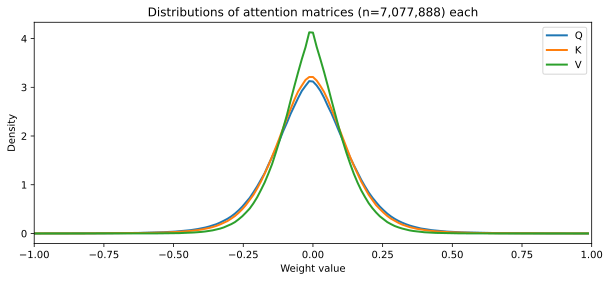

In [ ]:
bins = np.linspace(-1,1,151)

# init
all_q = np.array([])
all_k = np.array([])
all_v = np.array([])

n_emb = gpt2.transformer.wte.weight.shape[1]

# loop over all transformers and get their weights
for h_idx in range(len(gpt2.transformer.h)):

  # split into matrices
  q,k,v = torch.split(gpt2.transformer.h[h_idx].attn.c_attn.weight, n_emb, dim = 1)

  # add to the pile o' numbers
  all_q = np.concatenate((all_q, q.detach().flatten().numpy()), axis = 0)
  all_k = np.concatenate((all_k, k.detach().flatten().numpy()), axis = 0)
  all_v = np.concatenate((all_v, v.detach().flatten().numpy()), axis = 0)


# get histogram bins
yq, xq = np.histogram(all_q, bins = bins, density = True)
yk, xk = np.histogram(all_k, bins = bins, density = True)
yv, xv = np.histogram(all_v, bins = bins, density = True)

# and plot
plt.figure(figsize = (10,4))
plt.plot(xq[:-1], yq, linewidth = 2, label = 'Q')
plt.plot(xk[:-1], yk, linewidth = 2, label = 'K')
plt.plot(xv[:-1], yv, linewidth = 2, label = 'V')

plt.legend()
plt.gca().set(xlim = bins[[0,-1]], xlabel = 'Weight value', ylabel = 'Density',
              title = f'Distributions of attention matrices (n={len(all_q):,}) each')
plt.show()

# Do we really need Q?

* How to iterfere with models and run experiments (intro to causal mechinterp)
* That even small manipulations to the models can cause major qualitative damage, due to propagation of errors.

1. Connect to the GPU
2. Import the GPT2-small twice with different variable names
3. Put one model on the GPU and leave the other on the CPU
4. Generate some text

In [ ]:
import torch
from transformers import AutoModelForCausalLM, GPT2Tokenizer

Import GPT2 and push a copy to the GPU

In [ ]:
gpt2_orig = AutoModelForCausalLM.from_pretrained('gpt2') # one gpt2 which we won't modify
gpt2      = AutoModelForCausalLM.from_pretrained('gpt2')

tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

## Random Number Generation on different devices

In [ ]:
# use GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [ ]:
# push model to the GPU - the one we will modify
gpt2.to(device)

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
# generate some input
x = torch.tensor(tokenizer.encode('Hello, how are you today?')).unsqueeze(0)
x

tensor([[15496,    11,   703,   389,   345,  1909,    30]])

In [ ]:
### on the CPU
torch.manual_seed(42) # seed the rng
out = gpt2_orig.generate(x,
                         temperature=1,
                         do_sample = True,
                         max_length = 100,
                         pad_token_id = tokenizer.eos_token_id)
print(tokenizer.decode(out[0].tolist()))

Hello, how are you today? I'm sorry to have asked you this."

"It's fine then," said the man. "How do you feel about that?"

The man sighed and held out his hand. "It's what I want. What's going on?"

"It's a mistake," said Mrs. Murnane. "As you would say, you have an obligation to make your needs known. If we're going to talk about your new boyfriend


In [ ]:
### on the GPU
torch.manual_seed(42) # seed the rng
out = gpt2.generate(x.to(device),
                    temperature=1,
                    do_sample = True,
                    max_length = 100,
                    pad_token_id = tokenizer.eos_token_id)
print(tokenizer.decode(out[0].tolist()))

# Some differences between CPU and GPU are expected due to differential rounding
# but the rng seed is different on the GPU and CPU

Hello, how are you today? What you did today is something I really wished had never happened in my life." she replied, "Well my son was born with a big head and I was always worried about him even though he's a little older than him. He's a bit shy and he's very good at playing with his toy. So when I saw him get hit and struck by a car, I just could not believe the thing he did. He's like a jack-in-


So, even though we have random number generator seed set on 42, we use one on CPU and one on GPU, i.e. we have two different rng's. We need to assure that we use same processor hardware.

## Reset gpt2

In [ ]:
# use this code to copy the roginal params onto a modified model
gpt2.load_state_dict(gpt2_orig.state_dict())

<All keys matched successfully>

## Replace one Q matrix

In [ ]:
# size of Q matrix
n_emb = gpt2.transformer.wte.weight.shape[1] # we want just Q and its glued QKV
size_of_Q = gpt2.transformer.h[0].attn.c_attn.weight[:,:n_emb].shape
size_of_Q

torch.Size([768, 768])

In [ ]:
# get the matrix
q = gpt2.transformer.h[0].attn.c_attn.weight[:,:n_emb] # we take just Q

# create noise with matching statistics
mean = q.mean()
std  = q.std()
noise = torch.randn_like(q)*std + mean

# replace the values in q
gpt2.transformer.h[0].attn.c_attn.weight.data[:,:n_emb] = noise

In [ ]:
# confirm that the weights really have changed
print(gpt2.transformer.h[0].attn.c_attn.weight[:10,1])
print(gpt2_orig.transformer.h[0].attn.c_attn.weight[:10,1])

tensor([-0.1282, -0.2329, -0.1869,  0.3391,  0.2995, -0.4119, -0.2515,  0.4696,
        -0.2058, -0.1781], device='cuda:0', grad_fn=<SelectBackward0>)
tensor([-0.2614,  0.1473,  0.0695, -0.1884,  0.1678, -0.0265, -0.0360,  0.2333,
         0.0740,  0.2161], grad_fn=<SelectBackward0>)


In [ ]:
# rerun on the GPU
torch.manual_seed(42)
out = gpt2.generate(x.to(device),
                    temperature = 1,
                    do_sample = True,
                    max_length = 100,
                    pad_token_id = tokenizer.eos_token_id)
print('Text with random Q:\n\n\n',tokenizer.decode(out[0].tolist()))

Text with random Q:


 Hello, how are you today?

I am in the process of making a new game, and I have a long-planned time to do it (this will be the first year in my schedule) and my other 3-game was my big-game of the day. I came to my usual 3-game and I came to my other 3-game and I will do it at the end of the week in the end of the year I was in the first year in my schedule


Text with trained Q:

```
Hello, how are you today? What you did today is something I really wished had never happened in my life." she replied, "Well my son was born with a big head and I was always worried about him even though he's a little older than him. He's a bit shy and he's very good at playing with his toy. So when I saw him get hit and struck by a car, I just could not believe the thing he did. He's like a jack-in-
```

## Lobotomize the model

In [ ]:
# reset the model to its original parameters
gpt2.load_state_dict(gpt2_orig.state_dict())

<All keys matched successfully>

In [ ]:
# model output pre-changes
print('** Using all original Q values:')

x = torch.tensor(tokenizer.encode('I went to the market to buy')).unsqueeze(0)
out = gpt2.generate(x.to(device),
                    temperature = 1,
                    do_sample = True,
                    max_length = 50,
                    pad_token_id = tokenizer.eos_token_id)
print(tokenizer.decode(out[0].tolist()))

** Using all original Q values:
I went to the market to buy my first two pairs of underwear. It turned out to have been more comfortable than I thought it would be–more in the shape and shape of your typical pants. It didn't really bother me, though. It


In [ ]:
# loop over all transformer heads, replace Q, and give the same input
for h_idx in range(len(gpt2.transformer.h)):

  print(f'\n\n** Now replacing Q{h_idx} with noise:')

  # get the matrix
  q = gpt2.transformer.h[h_idx].attn.c_attn.weight[:,:n_emb]

  # create noise with matching statistics
  mean  = q.mean()
  std   = q.std()
  noise = torch.rand_like(q)*std + mean

  # replace the values in q
  gpt2.transformer.h[h_idx].attn.c_attn.weight.data[:,:n_emb] = noise

  # generate the output
  out = gpt2.generate(x.to(device),
                      temperature = 1,
                      do_sample = True,
                      max_length = 50,
                      pad_token_id = tokenizer.eos_token_id)
  print(tokenizer.decode(out[0].tolist()))



** Now replacing Q0 with noise:
I went to the market to buy something. I know how you like to go to the show and get the best. When I saw they were, I thought, it was a little, a little, a little, but I was there, it


** Now replacing Q1 with noise:
I went to the market to buy a new car but they could not take my order because I had no credit card in my order to purchase a new car," Halt, "I bought an old car because I had no credit card in my order


** Now replacing Q2 with noise:
I went to the market to buy what I did with a new, original and new T3.

For a while while and while while while while I bought a new T3 that,


for me I was a new, new


** Now replacing Q3 with noise:
I went to the market to buy a brand new car; I will buy a brand new car." I am going to buy a brand new in I am going to buy brand new car and I am going to buy brand new  Am being am going


** Now replacing Q4 with noise:
I went to the market to buy the R-T (R, with I like - R-1-1 R-1)2 -R-5) -1-I -1 (1